In [2]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,image_path,style,ID
0,./images/0.png,cartoon,0
1,./images/1.png,cartoon,1
2,./images/2.png,cartoon,2
3,./images/3.png,cartoon,3
4,./images/4.png,cartoon,4


In [10]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train["style"] = enc.fit_transform(df_train["style"])
df_train.head()

,image_path,style,ID
0,./images/0.png,0,0
1,./images/1.png,0,1
2,./images/2.png,0,2
3,./images/3.png,0,3
4,./images/4.png,0,4


In [35]:
import torch

num_epochs = 6
batch_size = 32
learning_rate = 0.001

num_epochs

6

In [36]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image

train_transforms = T.Compose([
    T.Resize((227, 227)),
    T.ToTensor()
])

test_transforms = T.Compose([
    T.Resize((227, 227)),
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        label = self.df["style"].iloc[idx]
        img = Image.open(path)
        img = self.transform(img)
        label = torch.tensor(label, dtype=torch.float32).view(1)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)

train_dataset = MyDataset(df_1, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = MyDataset(df_2, test_transforms)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

train_dataset[0][0][0][0][0]

tensor(0.3412)

In [37]:
import torch.nn as nn
import torchvision

model = torchvision.models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.LazyLinear(1)
model = model.to("cuda")

criterion = nn.BCEWithLogitsLoss()
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [38]:
from tqdm import tqdm

def train(epoch):
    model.train()
    total_loss = 0
    for inputs, labels in tqdm(train_loader):
        inputs, labels = inputs.to("cuda"), labels.to("cuda")
        loss = criterion(model(inputs), labels)
        optim.zero_grad()
        loss.backward()
        optim.step()
        total_loss += loss.item()
    print("Epoch ", epoch)
    print("Training Loss ", total_loss/len(train_loader))

def test():
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to("cuda"), labels.to("cuda")
            loss = criterion(model(inputs), labels)
            total_loss += loss.item()
        print("Validation Loss ", total_loss/len(train_loader))

In [39]:
for i in range(1, num_epochs+1):
    train(i)
    test()

100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:05<00:00,  4.78it/s]


Epoch  1
Training Loss  0.13844600658863782
Validation Loss  0.03770015000249259


100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:04<00:00,  5.22it/s]


Epoch  2
Training Loss  0.038508682074025274
Validation Loss  0.0024011468118987976


100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:04<00:00,  5.60it/s]


...

Epoch  4
Training Loss  0.014493202404119075
Validation Loss  0.01815860973787494


100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:04<00:00,  5.17it/s]


Epoch  5
Training Loss  0.027179365806514397
Validation Loss  0.0017961626587202773


100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:04<00:00,  5.49it/s]


Epoch  6
Training Loss  0.036251269369386135
Validation Loss  0.006333161354996264


In [44]:
class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        img = Image.open(path)
        img = self.transform(img)
        return img

final_dataset = FinalDataset(df_test, test_transforms)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

final_dataset[0][0][0][0]

tensor(1.)

In [53]:
import numpy as np

model.eval()
preds = []

with torch.no_grad():
    for inputs in final_loader:
        inputs = inputs.to("cuda")
        outputs = torch.sigmoid(model(inputs)).cpu().numpy().flatten()
        preds.extend(outputs)

preds = (np.array(preds) > 0.5).astype("int")
preds[:10]

array([0, 1, 0, 1, 1, 0, 0, 1, 0, 1])

In [54]:
preds = enc.inverse_transform(preds)
preds[:10]

array(['cartoon', 'photo', 'cartoon', 'photo', 'photo', 'cartoon',
       'cartoon', 'photo', 'cartoon', 'photo'], dtype=object)

In [56]:
df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.ID,
    "answer": preds
})

df_1.head()

,subtaskID,datapointID,answer
0,1,981,cartoon
1,1,982,photo
2,1,983,cartoon
3,1,984,photo
4,1,985,photo


In [245]:
import cv2
paths = df_test.image_path

means = []
stds = []

for path in paths:
    img = Image.open(path)
    mean = np.array(img).mean()
    std = np.array(img).std()
    means.append(mean)
    stds.append(std)

df_imgs = pd.DataFrame({
    "mean": means,
    "std": stds
})

df_imgs.head()

,mean,std
0,225.374106,54.196960
1,89.747301,75.390310
2,201.698694,70.867381
3,100.370523,49.689749
4,142.666738,64.088608


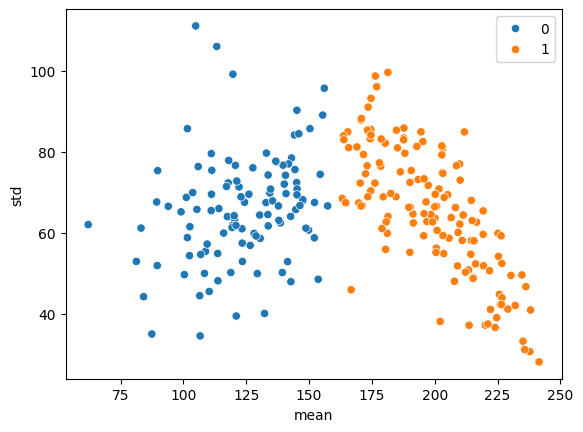

In [257]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = (np.array(df_imgs["mean"]) > 160).astype("int")

sns.scatterplot(x=df_imgs["mean"], y=df_imgs["std"], hue=labels)
plt.show()

In [260]:
labels = pd.Series(labels).map({0: "house", 1:"elephant"})

elephant


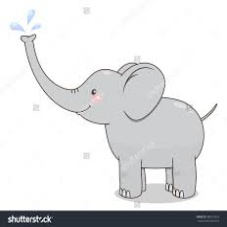

In [261]:
i = 0
print(labels[i])
Image.open(df_test.image_path[i])

house


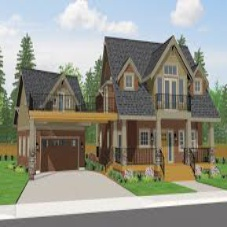

In [262]:
i = 4
print(labels[i])
Image.open(df_test.image_path[i])

In [263]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df_test.ID,
    "answer": labels
})

df_2.head()

,subtaskID,datapointID,answer
0,2,981,elephant
1,2,982,house
2,2,983,elephant
3,2,984,house
4,2,985,house


In [264]:
submission = pd.concat([df_1, df_2])
submission

,subtaskID,datapointID,answer
0,1,981,cartoon
1,1,982,photo
2,1,983,cartoon
3,1,984,photo
4,1,985,photo
...,...,...,...
241,2,1222,elephant
242,2,1223,house
243,2,1224,house
244,2,1225,elephant


In [265]:
submission.to_csv("submission.csv", index=False)